# Task 2


In [1]:
# imports
import itertools
import math

import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
import torch
import torch.nn as nn
import torch.optim as optim
from matplotlib.colors import LogNorm

torch.set_default_dtype(torch.double)

In [2]:
# constants
m, mu, k = 1.0, 5, 500   # mass, friction constant, spring constant

delta = mu / (2*m)
omega = np.sqrt(k - delta**2)   # sqrt(omega_0^2 - delta^2) with omega_0^2 = k

def A(phi):
    return 1 / (2*math.cos(phi))

phi = np.arctan(-delta / omega)

print("delta =, ", delta)
print("A(phi) = ", A(phi))
print("phi = ", phi)
print("omega = ", omega)

def x(t):
    return np.exp(-delta*t) * (2*A(phi) * np.cos(omega*t + phi))

delta =,  2.5
A(phi) =  0.5031546054266276
phi =  -0.11203764265090964
omega =  22.22048604328897


## Task 2.1


In [3]:
t_train = torch.linspace(0, 0.5, 10).view(-1, 1)  # shape (samples, features) = (10, 1), not (samples,)
y_train = x(t_train)

t_train, y_train

C:\Users\agrim\AppData\Local\Temp\ipykernel_29896\507325984.py:18: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  return np.exp(-delta*t) * (2*A(phi) * np.cos(omega*t + phi))


(tensor([[0.0000],
         [0.0556],
         [0.1111],
         [0.1667],
         [0.2222],
         [0.2778],
         [0.3333],
         [0.3889],
         [0.4444],
         [0.5000]]),
 tensor([[ 1.0000e+00],
         [ 3.7966e-01],
         [-5.3937e-01],
         [-5.9742e-01],
         [ 6.5368e-02],
         [ 4.9007e-01],
         [ 2.3201e-01],
         [-2.3794e-01],
         [-3.1242e-01],
         [ 7.5858e-04]]))

## Task 2.2


In [4]:
class Net(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(1, 10), nn.Tanh(), nn.Linear(10, 1))

    def forward(self, x):
        return self.net(x)

In [7]:
model = Net()
criterion = nn.MSELoss()
optimizer = optim.Adam(model.parameters(), lr=0.01)

num_epoch = 10000
model.train()
for epoch in range(num_epoch):
    optimizer.zero_grad()
    train_loss = criterion(model(t_train), y_train)
    train_loss.backward()
    optimizer.step()

    if (epoch + 1) % 1000 == 0:
        print(f'Epoch [{epoch+1}/{num_epoch}], Loss: {train_loss.item():.6f}')

Epoch [1000/10000], Loss: 0.021136
Epoch [2000/10000], Loss: 0.000800
Epoch [3000/10000], Loss: 0.000340
Epoch [4000/10000], Loss: 0.000174
Epoch [5000/10000], Loss: 0.000092
Epoch [6000/10000], Loss: 0.000053
Epoch [7000/10000], Loss: 0.000037
Epoch [8000/10000], Loss: 0.000030
Epoch [9000/10000], Loss: 0.000026
Epoch [10000/10000], Loss: 0.000024


C:\Users\agrim\AppData\Local\Temp\ipykernel_29896\507325984.py:18: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  return np.exp(-delta*t) * (2*A(phi) * np.cos(omega*t + phi))


torch.Size([100, 1]) torch.Size([100, 1]) torch.Size([100, 1])


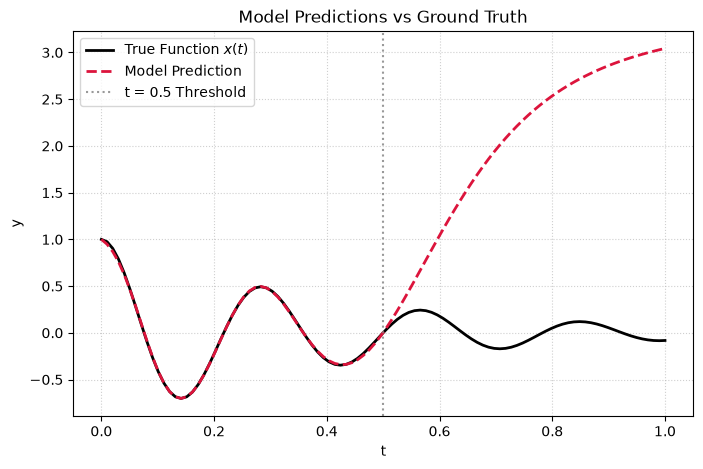

In [8]:
model.eval()

with torch.no_grad():
    t_test = torch.linspace(0, 1, 100).view(-1, 1)
    y_pred = model(t_test)
    y_true = x(t_test)

    print(t_test.shape, y_pred.shape, y_true.shape)

# True values vs predictions
plt.figure(figsize=(8, 5))
plt.plot(t_test, y_true, label='True Function $x(t)$', color='black', linewidth=2)
plt.plot(t_test, y_pred, label='Model Prediction', color='crimson', linestyle='--', linewidth=2)
plt.axvline(x=0.5, color='gray', linestyle=':', alpha=0.8, label='t = 0.5 Threshold')
plt.title('Model Predictions vs Ground Truth')
plt.xlabel('t')
plt.ylabel('y')
plt.legend()
plt.grid(True, linestyle=':', alpha=0.6)
plt.show()

In [9]:
print(f'Test Loss: {criterion(y_pred, y_true).item():.4f}')

Test Loss: 2.4405


## Task 2.3


In [15]:
# data points and collocation points
t_data = np.linspace(0, 0.5, 10)
x_data = x(t_data)
t_col = np.linspace(0, 1, 50)

In [16]:
global lam_phys, lam_ic
lam_phys = 1e-4
lam_ic = 1

def NN(t, W1, b1, W2, b2):
    return np.sum(W2 * np.tanh(W1*t + b1)) + b2

def dNN(t, W1, b1, W2, b2):
    return np.sum(W2 * W1 * (1 - np.tanh(W1*t + b1)**2))

def ddNN(t, W1, b1, W2, b2):
    tanh = np.tanh(W1*t + b1)
    return np.sum(-2 * W2 * W1**2 * tanh * (1 - tanh**2))

def residual(t, *p):
    """ODE residual x'' + (mu/m) x' + (k/m) x of the network at time t."""
    return ddNN(t, *p) + mu/m * dNN(t, *p) + k/m * NN(t, *p)

def loss(W1, b1, W2, b2):
    p = (W1, b1, W2, b2)
    L_data = sum((NN(t, *p) - x_i)**2 for t, x_i in zip(t_data, x_data)) / len(t_data)
    L_phys = sum(residual(t, *p)**2 for t in t_col) / len(t_col)
    L_ic = (NN(0, *p) - 1)**2 + dNN(0, *p)**2
    return L_data + lam_phys*L_phys + lam_ic*L_ic

def gradients(W1, b1, W2, b2):
    p = (W1, b1, W2, b2)
    dW1, db1, dW2, db2 = np.zeros_like(W1), np.zeros_like(b1), np.zeros_like(W2), 0.0

    # data term
    for t, x_i in zip(t_data, x_data):
        tanh = np.tanh(W1*t + b1)
        s = 1 - tanh**2
        w = 2/len(t_data) * (NN(t, *p) - x_i)

        dW1 += w * W2 * s * t
        db1 += w * W2 * s
        dW2 += w * tanh
        db2 += w

    # physics term
    for t in t_col:
        tanh = np.tanh(W1*t + b1)
        s = 1 - tanh**2
        c = lam_phys * 2/len(t_col) * residual(t, *p)

        # eq (42)
        dr_dW1 = (-4 * W2 * W1 * tanh * s
                  - 2 * W2 * W1**2 * t * s**2
                  + 4 * W2 * W1**2 * t * tanh**2 * s
                  + mu/m * (W2 * s - 2 * W2 * W1 * t * tanh * s)
                  + k/m * W2 * t * s)

        # eq (43)
        dr_dW2 = -2 * W1**2 * tanh * s + mu/m * W1 * s + k/m * tanh

        # biases: same as for W1 but without the factor t from the inner derivative
        dr_db1 = (-2 * W2 * W1**2 * s**2
                  + 4 * W2 * W1**2 * tanh**2 * s
                  + mu/m * (-2 * W2 * W1 * tanh * s)
                  + k/m * W2 * s)

        dW1 += c * dr_dW1
        db1 += c * dr_db1
        dW2 += c * dr_dW2
        db2 += c * (k/m)

    # initial conditions (t = 0)
    tanh0 = np.tanh(b1)
    s0 = 1 - tanh0**2
    NN0, dNN0 = NN(0, *p), dNN(0, *p)

    dW1 += lam_ic * 2 * dNN0 * W2 * s0
    db1 += lam_ic * (2 * (NN0 - 1) * W2 * s0 - 4 * dNN0 * W2 * W1 * tanh0 * s0)
    dW2 += lam_ic * (2 * (NN0 - 1) * tanh0 + 2 * dNN0 * W1 * s0)
    db2 += lam_ic * 2 * (NN0 - 1)

    return dW1, db1, dW2, db2

## Task 2.4


In [17]:
epsilon = 1e-5

def get_params(model):
    l1, l2 = model.net[0], model.net[2]
    return (l1.weight.detach().numpy()[:, 0], l1.bias.detach().numpy(),
            l2.weight.detach().numpy()[0, :], l2.bias.detach().numpy()[0])

net = Net()
W1, b1, W2, b2 = get_params(net)
dW1, db1, dW2, db2 = gradients(W1, b1, W2, b2)

# central finite differences w.r.t. W1, perturbing one entry at a time
dW1_fd = np.array([(loss(W1 + e, b1, W2, b2) - loss(W1 - e, b1, W2, b2)) / (2*epsilon)
                   for e in epsilon * np.eye(len(W1))])

print(dW1)
print(dW1_fd)
print(" error:", np.linalg.norm(dW1 - dW1_fd) / np.linalg.norm(dW1_fd))

[ 1.88775249  3.8502998  -3.58069234 -3.56968268  1.36246625 -0.45645837
 -1.41100636  1.43255611 -0.77640312 -0.84118938]
[ 1.88775249  3.8502998  -3.58069234 -3.56968268  1.36246625 -0.45645836
 -1.41100636  1.43255611 -0.77640312 -0.84118938]
 error: 1.1628741012545299e-10


## Task 2.5


### Hyperparameter tuning (Lambda values)


In [26]:
# Settings for the sweep (the final pass further down uses 10000 Adam epochs / L-BFGS iterations)
adam_epochs = 3000
lbfgs_iter = 5000
SEEDS = [0, 1, 2, 3, 4]
LAM_PHYS_GRID = [1e-5, 1e-4, 1e-3, 1e-2, 0.1, 1, 10]   # one value per decade
LAM_IC_GRID = [0, 0.03, 0.1, 0.3, 1]
OPTIMIZER = "Adam+LBFGS"                                # "Adam", "LBFGS" or "Adam+LBFGS"

# Evaluation grid (t = 0.5 is where the training data ends)
t_eval = torch.linspace(0, 1, 50).view(-1, 1)
x_eval = x(t_eval)
mask_extrap = t_eval[:, 0] > 0.5

def train(lam_p, lam_i, seed, optim, final=False):
    global lam_phys, lam_ic
    lam_phys, lam_ic = lam_p, lam_i   # NOTE: local names only, loss()/gradients() still read the globals from 2.3
    torch.manual_seed(seed)
    model = Net()

    def closure():
        W1, b1, W2, b2 = get_params(model)
        L = loss(W1, b1, W2, b2)
        grads = gradients(W1, b1, W2, b2)

        # hand the NumPy gradients back to torch (same order as model.parameters()) for Adam / L-BFGS
        for p, g in zip(model.parameters(), grads):
            p.grad = torch.tensor(g).reshape(p.shape)
        return torch.tensor(L)

    n_adam = 10000 if final else adam_epochs
    n_lbfgs = 10000 if final else lbfgs_iter

    if "Adam" in optim:
        optimizer = torch.optim.Adam(model.parameters(), lr=0.01)
        for i in range(n_adam):
            L = closure()
            optimizer.step()
            if i % 1000 == 0:
                print(i, L)

    if "LBFGS" in optim:
        optimizer = torch.optim.LBFGS(model.parameters(),
                                      lr=1.0,
                                      max_iter=n_lbfgs,
                                      max_eval=1.5*n_lbfgs,
                                      tolerance_grad=1e-10,
                                      tolerance_change=1e-14,
                                      history_size=50,
                                      line_search_fn="strong_wolfe")
        optimizer.step(closure)
        print("LBFGS optimized:", closure().item())

    with torch.no_grad():
        err = (model(t_eval) - x_eval) ** 2
    return model, err.mean().item(), err[mask_extrap].mean().item()

C:\Users\agrim\AppData\Local\Temp\ipykernel_29896\507325984.py:18: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  return np.exp(-delta*t) * (2*A(phi) * np.cos(omega*t + phi))


In [27]:
# The sweep to check all combinations
results = []   # (lam_phys, lam_ic, median full MSE, worst full MSE, median extrapolation MSE)
for lp, li in itertools.product(LAM_PHYS_GRID, LAM_IC_GRID):
    full, extrap = np.array([train(lp, li, s, OPTIMIZER)[1:] for s in SEEDS]).T
    row = (lp, li, np.median(full), full.max(), np.median(extrap))
    results.append(row)
    print(f"lam_phys={lp:<7g} lam_ic={li:<5g} "
          f"median_full={row[2]:.3e} worst={row[3]:.3e} median_extrap={row[4]:.3e}", flush=True)

results.sort(key=lambda r: r[2])
print("\nTop 5 (lam_phys, lam_ic, median_full_MSE, worst_MSE, median_extrap_MSE):")
for r in results[:5]:
    print(f"  {r[0]:<7g} {r[1]:<5g} {r[2]:.3e} {r[3]:.3e} {r[4]:.3e}")

0 tensor(0.2308)
1000 tensor(0.0406)
2000 tensor(0.0184)
LBFGS optimized: 0.0003734062112576089
0 tensor(1.1638)
1000 tensor(0.2030)
2000 tensor(0.1600)
LBFGS optimized: 3.346117382725422e-06
0 tensor(0.2219)
1000 tensor(0.0511)
2000 tensor(0.0184)
LBFGS optimized: 0.00034285086711537116
0 tensor(0.5305)
1000 tensor(0.1173)
2000 tensor(0.0201)
LBFGS optimized: 0.0006553349604358525
0 tensor(0.3554)
1000 tensor(0.1529)
2000 tensor(0.0155)
LBFGS optimized: 1.4429279760936815e-05
lam_phys=1e-05   lam_ic=0     median_full=5.609e-04 worst=1.363e-03 median_extrap=1.119e-03
0 tensor(0.2548)
1000 tensor(0.0449)
2000 tensor(0.0135)
LBFGS optimized: 5.538309950029626e-06
0 tensor(1.2228)
1000 tensor(0.2399)
2000 tensor(0.2381)
LBFGS optimized: 0.0013328943265749603
0 tensor(0.2489)
1000 tensor(0.0564)
2000 tensor(0.0139)
LBFGS optimized: 4.4268753320881895e-06
0 tensor(0.5431)
1000 tensor(0.2359)
2000 tensor(0.0620)
LBFGS optimized: 5.014791759493393e-05
0 tensor(0.3910)
1000 tensor(0.2379)
2000

In [28]:
# Retrain with our best lambdas (final pass)
best_lp, best_li = results[0][:2]
net, full, _ = train(best_lp, best_li, seed=SEEDS[0], optim=OPTIMIZER, final=True)
with torch.no_grad():
    pred = net(t_eval)

0 tensor(1.7211)
1000 tensor(0.5202)
2000 tensor(0.5198)
3000 tensor(0.5193)
4000 tensor(0.5192)
5000 tensor(0.5192)
6000 tensor(0.5192)
7000 tensor(0.5192)
8000 tensor(0.5192)
9000 tensor(0.5192)
LBFGS optimized: 2.2094404480535798e-05


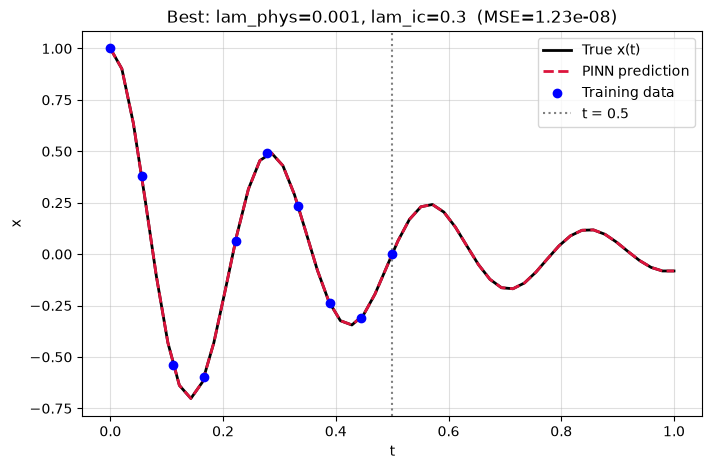

<Axes: >

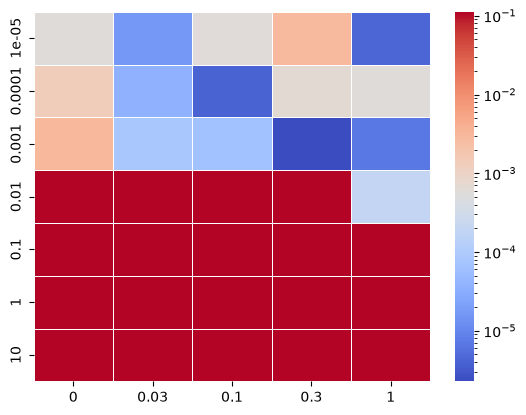

In [29]:
plt.figure(figsize=(8, 5))
plt.plot(t_eval, x_eval, "k", lw=2, label="True x(t)")
plt.plot(t_eval, pred, "--", color="crimson", lw=2, label="PINN prediction")
plt.scatter(t_data, x_data, color="blue", zorder=3, label="Training data")
plt.axvline(0.5, color="gray", ls=":", label="t = 0.5")
plt.title(f"Best: lam_phys={best_lp:g}, lam_ic={best_li:g}  (MSE={full:.2e})")
plt.xlabel("t"); plt.ylabel("x"); plt.legend(); plt.grid(alpha=0.4)
plt.show()

# Heatmap of the median full-range MSE over the lambda grid
grid = sorted(results, key=lambda r: r[:2])
phys, ic = sorted({r[0] for r in results}), sorted({r[1] for r in results})
sns.heatmap(np.array([r[2] for r in grid]).reshape(len(phys), len(ic)),
            xticklabels=ic, yticklabels=phys,
            norm=LogNorm(), cmap="coolwarm", linewidths=0.5)

<>:34: SyntaxWarning: "\i" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\i"? A raw string is also an option.
<>:50: SyntaxWarning: "\l" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\l"? A raw string is also an option.
<>:50: SyntaxWarning: "\l" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\l"? A raw string is also an option.
<>:34: SyntaxWarning: "\i" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\i"? A raw string is also an option.
<>:50: SyntaxWarning: "\l" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\l"? A raw string is also an option.
<>:50: SyntaxWarning: "\l" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\l"? A raw string is also an option.
C:\Users\agrim\AppData\Local\Temp\ipykernel_29896\2936844492.py:34: SyntaxWa

Regime     lam_p    lam_ic   L_tot       L_data      L_phys      L_IC        MSE (0,1)  
0 tensor(0.4705)
1000 tensor(0.1420)
2000 tensor(0.0599)
3000 tensor(0.0330)
4000 tensor(0.0187)
5000 tensor(0.0116)
6000 tensor(0.0074)
7000 tensor(0.0054)
8000 tensor(0.0045)
9000 tensor(0.0032)
LBFGS optimized: 1.1631418804158004e-05
Weak       1e-05    0.3      1.163e-05   3.138e-07   1.131e+00   2.305e-08   2.089e-07  
0 tensor(1.7211)
1000 tensor(0.5202)
2000 tensor(0.5198)
3000 tensor(0.5193)
4000 tensor(0.5192)
5000 tensor(0.5192)
6000 tensor(0.5192)
7000 tensor(0.5192)
8000 tensor(0.5192)
9000 tensor(0.5192)
LBFGS optimized: 2.2094404480535798e-05
Optimal    0.001    0.3      2.209e-05   2.263e-08   2.207e-02   1.536e-08   1.232e-08  
0 tensor(12633.0457)
1000 tensor(0.7749)
2000 tensor(0.6059)
3000 tensor(0.5466)
4000 tensor(0.5362)
5000 tensor(0.5341)
6000 tensor(0.5393)
7000 tensor(0.5372)
8000 tensor(0.5364)
9000 tensor(0.5345)
LBFGS optimized: 0.5244453852493347
Strong     10       0.

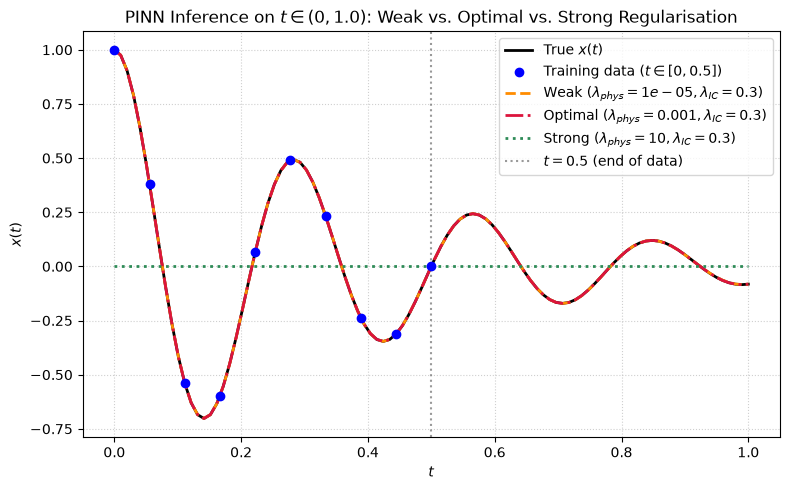

In [30]:
# Evaluation grid on t in (0, 1.0) as required by Task 2.5
t_eval_1 = torch.linspace(0, 1, 100).view(-1, 1)
x_eval_1 = x(t_eval_1)

def eval_losses(model, lp, li):
    W1, b1, W2, b2 = get_params(model)
    p = (W1, b1, W2, b2)
    L_data = sum((NN(t, *p) - x_i)**2 for t, x_i in zip(t_data, x_data)) / len(t_data)
    L_phys = sum(residual(t, *p)**2 for t in t_col) / len(t_col)
    L_ic = (NN(0, *p) - 1)**2 + dNN(0, *p)**2
    L_tot = L_data + lp * L_phys + li * L_ic
    with torch.no_grad():
        mse = ((model(t_eval_1) - x_eval_1) ** 2).mean().item()
    return L_tot, L_data, L_phys, L_ic, mse

# Define weak, optimal, and strong regularisation regimes
regimes = [
    ("Weak",    1e-5,    best_li),
    ("Optimal", best_lp, best_li),
    ("Strong",  10.0,    best_li),
]

models = {}
print(f"{'Regime':<10} {'lam_p':<8} {'lam_ic':<8} {'L_tot':<11} {'L_data':<11} {'L_phys':<11} {'L_IC':<11} {'MSE (0,1)':<11}")
for name, lp, li in regimes:
    m_reg, _, _ = train(lp, li, seed=SEEDS[0], optim=OPTIMIZER, final=True)
    models[name] = m_reg
    L_tot, L_data, L_phys, L_ic, mse = eval_losses(m_reg, lp, li)
    print(f"{name:<10} {lp:<8g} {li:<8g} {L_tot:<11.3e} {L_data:<11.3e} {L_phys:<11.3e} {L_ic:<11.3e} {mse:<11.3e}")

# Plot inference on t in (0, 1.0) for weak, optimal, and strong regularisation
plt.figure(figsize=(8, 5))
plt.plot(t_eval_1, x_eval_1, color="black", lw=2, label="True $x(t)$")
plt.scatter(t_data, x_data, color="blue", zorder=4, label="Training data ($t \in [0, 0.5]$)")

styles = {
    "Weak":    {"color": "darkorange", "ls": "--"},
    "Optimal": {"color": "crimson",    "ls": "-."},
    "Strong":  {"color": "seagreen",   "ls": ":"},
}

with torch.no_grad():
    for name, lp, li in regimes:
        pred = models[name](t_eval_1)
        plt.plot(
            t_eval_1, pred,
            lw=2,
            color=styles[name]["color"],
            linestyle=styles[name]["ls"],
            label=f"{name} ($\lambda_{{phys}}={lp:g}, \lambda_{{IC}}={li:g}$)"
        )

plt.axvline(0.5, color="gray", ls=":", alpha=0.8, label="$t = 0.5$ (end of data)")
plt.title("PINN Inference on $t \\in (0, 1.0)$: Weak vs. Optimal vs. Strong Regularisation")
plt.xlabel("$t$")
plt.ylabel("$x(t)$")
plt.legend()
plt.grid(True, linestyle=":", alpha=0.6)
plt.tight_layout()
plt.savefig("task25_inference.png", dpi=300)
plt.show()
